In [15]:
import sys
import os
import json
import numpy as np
import scipy as sp
import pandas as pd

import importlib

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils

from utils import ai_slob

In [16]:
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(analysis_utils)

importlib.reload(ai_slob)

<module 'utils.ai_slob' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/ai_slob.py'>

In [17]:
# specific

from sklearn.decomposition import PCA, TruncatedSVD
from matplotlib import pyplot as plt

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_worm import read_utils

In [18]:
importlib.reload(read_utils)

<module 'utils_worm.read_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/worm-2025-fieseler/notebooks/analysis/../../src/utils_worm/read_utils.py'>

In [19]:
file_ids = range(0, 33 + 1)

In [20]:
filenames = analysis_utils.read_filenames('worm', file_ids)

In [22]:
dimensionaities = np.array([np.load(f'../../out/plots/manifolds/{filename}/gating_space_dim.npy') for filename in filenames])[:5]

In [28]:
dimensionaities = np.hstack((np.zeros((dimensionaities.shape[0], 1)), dimensionaities))

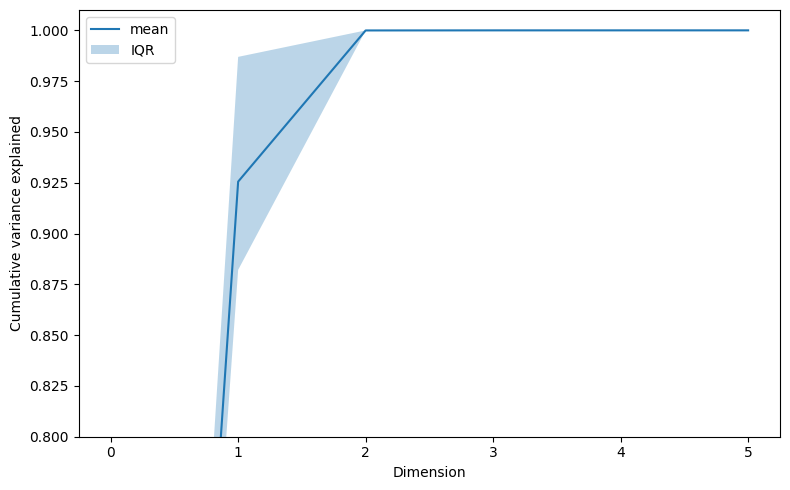

In [34]:
# Compute cumulative sums for each sample
cumulative_dims = np.cumsum(dimensionaities, axis=1)

# Compute mean and interquartile range (IQR) across samples for each dimension index
dim_mean = np.mean(cumulative_dims, axis=0)
dim_q25 = np.percentile(cumulative_dims, 25, axis=0)
dim_q75 = np.percentile(cumulative_dims, 75, axis=0)

# Plot
plt.figure(figsize=(8, 5))
plt.xticks(range(dimensionaities.shape[1]))
plt.plot(dim_mean, label='mean')
plt.fill_between(np.arange(len(dim_mean)), dim_q25, dim_q75, alpha=0.3, label='IQR')
plt.xlabel('Dimension')
plt.ylabel('Cumulative variance explained')
plt.legend()

plt.ylim(0.8, 1.01)

plt.tight_layout()
plt.savefig(os.path.join(os.path.expanduser('~'), 'Desktop/dims_worm.png'), bbox_inches='tight', dpi=300)
plt.show()